# NA'VI SENTINMENT ANALYSIS 💬
🧑‍💻 Dung Nguyen<br>
🐦 Elmhurst University<br>
📧 dung.nguyen@365.elmhurst.edu

## Libraries 📚

In [1]:
import pandas as pd
from sklearn.feature_selection import f_classif
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from PIL import Image
import requests
from io import BytesIO

## Preprocessing 🧹

Load the dataset from my GitHub repository.

In [2]:
corpus_raw = pd.read_csv("https://raw.githubusercontent.com/nguyend77/navi_nlp/refs/heads/main/corpus/corpus_raw.csv")
corpus_raw.head()

,na'vi,english,positive
0,Oeri ta peyä fahew akewong ontu teya längu.,My nose is full of his alien smell.,0
1,"Tewti, ma Prrton! Plltxe nga nìltsan!","Wow, Prrton! You speak well!",1
2,Kaltxì. Ngaru lu fpom srak?,"Hello, how are you?",1
3,Tsun oe ngahu nìNa'vi pivängkxo a fì'u oeru pr...,It's a pleasure to be able to chat with you in...,1
4,Fìskxawngìri tsap'alute sengi oe,I apologise for this moron.,0


In [3]:
def clean(string):
  lowercase = string.lower()
  new_string = ""
  for char in lowercase:
    if char in ["'", ",", ".", "!", "?", ":", "(", ")"]:
      new_string += ""
    else:
      new_string += char
  return new_string

def preprocess(df):
  df["na'vi"] = df["na'vi"].apply(clean)
  return df.drop('english', axis='columns')

corpus_clean = preprocess(corpus_raw)
corpus_clean.to_csv('corpus_clean.csv', index=False)
corpus_clean.head()

,na'vi,positive
0,oeri ta peyä fahew akewong ontu teya längu,0
1,tewti ma prrton plltxe nga nìltsan,1
2,kaltxì ngaru lu fpom srak,1
3,tsun oe ngahu nìnavi pivängkxo a fìu oeru prrt...,1
4,fìskxawngìri tsapalute sengi oe,0


Sample size

In [4]:
corpus_clean.shape

(404, 2)

## NLP Feature Extraction 🔍
Bag-of-Words

In [5]:
vocab = set()
for sentence in corpus_clean["na'vi"]:
  for word in sentence.split():
    vocab.add(word)
vocab = list(vocab)
len(vocab)

1026

In [6]:
bag_of_words = pd.DataFrame(0, index=range(len(corpus_clean)), columns=vocab)
for i, sentence in enumerate(corpus_clean["na'vi"]):
    for word in sentence.split():
        if word in vocab:
            bag_of_words.loc[i, word] += 1
bag_of_words.shape

(404, 1026)

In [7]:
corpus_final = pd.concat([corpus_clean, bag_of_words], axis='columns')
corpus_final.shape

(404, 1028)

## Defining Inputs and Outputs ⚙️

### Identify features (x) and target (y)

In [8]:
x = corpus_final.drop(["na'vi", "positive"], axis='columns')
y = corpus_final['positive']

### Dimensionality Reduction

In [9]:
f_scores, p_values = f_classif(x, y)
feature_scores_df = pd.DataFrame({'Feature': x.columns, 'F_Score': f_scores, 'P_Value': p_values})
feature_scores_df = feature_scores_df.sort_values(by='F_Score', ascending=False)
feature_scores_df.head()

,Feature,F_Score,P_Value
891,ke,42.103592,2.549845e-10
319,sì,8.731559,3.311500e-03
208,rää,8.364148,4.034881e-03
912,set,8.364148,4.034881e-03
406,irayo,7.722772,5.708681e-03


In [10]:
threshold = 0.1
selected_features = feature_scores_df[feature_scores_df['P_Value'] < threshold]['Feature']
len(selected_features)

61

### Train-Test Split

In [11]:
x_reduced = x[selected_features]
x_train, x_test, y_train, y_test = train_test_split(x_reduced, y, test_size=0.2, random_state=42, stratify=y)
print(y_train.value_counts())
print(y_test.value_counts())

positive
1    167
0    156
Name: count, dtype: int64
positive
1    42
0    39
Name: count, dtype: int64


## Building Models 🔢

### Logistic Regression 🥇

In [12]:
lgr_model = LogisticRegression()
lgr_model.fit(x_train, y_train)
y_pred_lgr = lgr_model.predict(x_test)
print(classification_report(y_test, y_pred_lgr))

              precision    recall  f1-score   support

           0       0.91      0.54      0.68        39
           1       0.69      0.95      0.80        42

    accuracy                           0.75        81
   macro avg       0.80      0.75      0.74        81
weighted avg       0.80      0.75      0.74        81



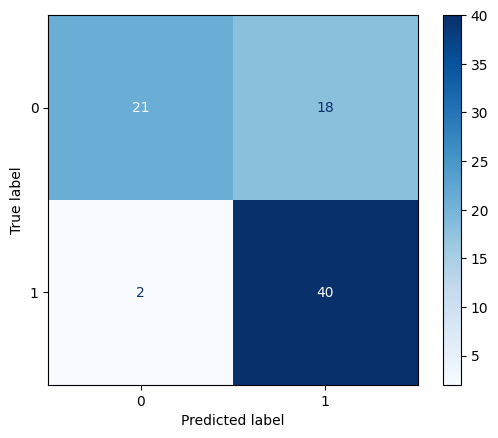

In [13]:
cm_lgr = ConfusionMatrixDisplay.from_estimator(lgr_model, x_test, y_test, cmap='Blues')

### Support Vector Machine 🥈

In [14]:
svm_model = SVC()
svm_model.fit(x_train, y_train)
y_pred_svm = svm_model.predict(x_test)
print(classification_report(y_test, y_pred_svm))

              precision    recall  f1-score   support

           0       0.87      0.51      0.65        39
           1       0.67      0.93      0.78        42

    accuracy                           0.73        81
   macro avg       0.77      0.72      0.71        81
weighted avg       0.77      0.73      0.72        81



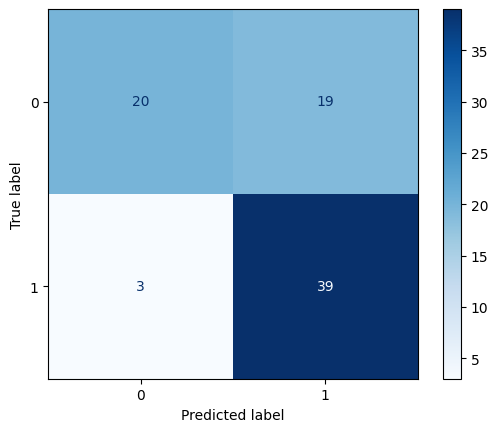

In [15]:
cm_svm = ConfusionMatrixDisplay.from_estimator(svm_model, x_test, y_test, cmap='Blues')

### k Nearest Neighbors 🥉

In [16]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(x_train, y_train)
y_pred_knn = knn_model.predict(x_test)
print(classification_report(y_test, y_pred_knn))

              precision    recall  f1-score   support

           0       0.88      0.38      0.54        39
           1       0.62      0.95      0.75        42

    accuracy                           0.68        81
   macro avg       0.75      0.67      0.65        81
weighted avg       0.75      0.68      0.65        81



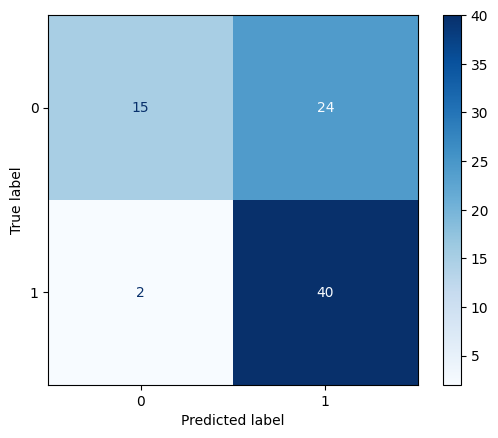

In [17]:
cm_knn = ConfusionMatrixDisplay.from_estimator(knn_model, x_test, y_test, cmap='Blues')

## Et voilà! 👌

In [18]:
def display_img(url):
  response = requests.get(url)
  img = Image.open(BytesIO(response.content))
  fig, ax = plt.subplots()
  ax.imshow(img)
  ax.axis('off')
  plt.show()

def predict_sentence(string):
  string = clean(string)
  bow = pd.DataFrame(0, index=range(1), columns=selected_features)
  for word in string.split():
    if word in selected_features:
      bow.loc[0, word] += 1
  result = lgr_model.predict(bow)[0]
  if result == 1:
    print('Positive')
    display_img('https://raw.githubusercontent.com/nguyend77/navi_nlp/main/display_result/positive.png')
  else:
    print('Negative')
    display_img('https://raw.githubusercontent.com/nguyend77/navi_nlp/main/display_result/negative.png')

Positive


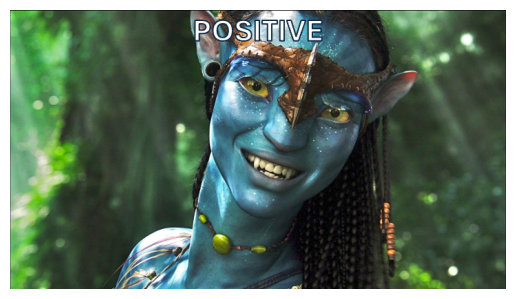

In [19]:
predict_sentence('Oel ngati kameie!')